<a href="https://colab.research.google.com/github/24csl12-art/Unit-Test---Deep-Learning/blob/main/RNN_Language_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving dataset.csv to dataset (1).csv


In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, Dense, Dropout

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.21.0


In [ ]:
df = pd.read_csv("dataset.csv")

print(df.head())
print(df.columns)
print(df.shape)

                                                Text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch
Index(['Text', 'language'], dtype='object')
(22000, 2)


In [ ]:
# 1. Encode target labels
le = LabelEncoder()
y = le.fit_transform(df['language'])
num_classes = len(le.classes_)
print(f"Number of classes (languages): {num_classes}")

# 2. Tokenize and pad the text sequences
max_words = 10000
max_len = 100

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(df['Text'])

sequences = tokenizer.texts_to_sequences(df['Text'])
X = pad_sequences(sequences, maxlen=max_len, padding='post', truncating='post')

# 3. Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

Number of classes (languages): 22
X_train shape: (17600, 100)
X_test shape: (4400, 100)


In [ ]:
# Change these names if your CSV uses different columns
df = df[["Text", "language"]].copy()

# Remove rows with missing values
df = df.dropna(subset=["Text", "language"])

# Convert text and labels to strings
df["Text"] = df["Text"].astype(str)
df["language"] = df["language"].astype(str).str.strip()

# Remove empty text and empty labels
df = df[
    (df["Text"].str.strip() != "") &
    (df["language"] != "")
].copy()

# Remove duplicate text-label pairs
df = df.drop_duplicates(subset=["Text", "language"])

# Clean text
def clean_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["Text"] = df["Text"].apply(clean_text)

print("Dataset cleaned successfully!")
print(df["language"].value_counts())

Dataset cleaned successfully!
language
Japanese      1000
Thai          1000
Korean        1000
Chinese       1000
Urdu          1000
Turkish       1000
Romanian      1000
English       1000
Persian       1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64


In [ ]:
# Build the LSTM model
embedding_dim = 64

model = Sequential([
    Embedding(input_dim=max_words, output_dim=embedding_dim, input_length=max_len),
    LSTM(64, dropout=0.2, recurrent_dropout=0.2),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

# Train the model
epochs = 5
batch_size = 64

history = model.fit(
    X_train, y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_test, y_test),
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
275/275 ━━━━━━━━━━━━━━━━━━━━ 58s 197ms/step - accuracy: 0.0767 - loss: 2.9662 - val_accuracy: 0.0918 - val_loss: 2.7448
Epoch 2/5
275/275 ━━━━━━━━━━━━━━━━━━━━ 69s 151ms/step - accuracy: 0.1094 - loss: 2.6451 - val_accuracy: 0.1432 - val_loss: 2.3778
Epoch 3/5
275/275 ━━━━━━━━━━━━━━━━━━━━ 44s 160ms/step - accuracy: 0.1486 - loss: 2.3541 - val_accuracy: 0.2014 - val_loss: 2.3374
Epoch 4/5
275/275 ━━━━━━━━━━━━━━━━━━━━ 85s 172ms/step - accuracy: 0.1948 - loss: 2.2279 - val_accuracy: 0.2625 - val_loss: 1.9761
Epoch 5/5
275/275 ━━━━━━━━━━━━━━━━━━━━ 105s 257ms/step - accuracy: 0.2767 - loss: 1.8750 - val_accuracy: 0.3595 - val_loss: 1.5218


In [ ]:
encoder = LabelEncoder()

y = encoder.fit_transform(df["language"])

print("Language labels:")
for i, language in enumerate(encoder.classes_):
    print(language, "=", i)

print("Number of languages:", len(encoder.classes_))

Language labels:
Arabic = 0
Chinese = 1
Dutch = 2
English = 3
Estonian = 4
French = 5
Hindi = 6
Indonesian = 7
Japanese = 8
Korean = 9
Latin = 10
Persian = 11
Portugese = 12
Pushto = 13
Romanian = 14
Russian = 15
Spanish = 16
Swedish = 17
Tamil = 18
Thai = 19
Turkish = 20
Urdu = 21
Number of languages: 22


In [ ]:
# Character-level tokenizer
tokenizer = Tokenizer(
    char_level=True,
    filters="",
    lower=False
)

tokenizer.fit_on_texts(df["Text"])

# Convert text to numbers
sequences = tokenizer.texts_to_sequences(df["Text"])

# Find a suitable sequence length
max_len = min(
    200,
    max(1, int(np.percentile(
        [len(s) for s in sequences], 95
    )))
)

# Pad shorter sequences and truncate longer ones
X = pad_sequences(
    sequences,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

vocab_size = len(tokenizer.word_index) + 1

print("Tokenization completed!")
print("Vocabulary size:", vocab_size)
print("Maximum sequence length:", max_len)
print("Input shape:", X.shape)
print("First numerical sequence:", X[0])

Tokenization completed!
Vocabulary size: 7187
Maximum sequence length: 200
Input shape: (21858, 200)
First numerical sequence: [ 26  10   2  14   2   5   7   1  21   9   7   7  63   3  10  12   4   1
   8  13   6   5  13  26   2  25   3   1  17   3  10   8   3  14   2   2
   6   4   7   4   1   5   4   5  21   1  17   3   4  21  13   7   3   7
   4   1  14   3  13   8   9  10   2  13  14   4   1   8  13   6   5  13
  26   2  25   3   1   9  10   4   1   3  21   3   1  10   4   4  21   3
   1  25   4  10  56   3   1  56   3   1   9   8  26   3  14   3   7  13
  10   7   1  17   3  10   8   3  14   2   2   6   4   7  13  12   1   5
   4   5  21   1  25   3  26  26   3   8   1   4  10  14  13   7   3  14
   3   1  10   3  21  13   5   2  14   4   8   2   1   7  13   5  12   2
  14 120   6  26   2   1   3   3   8   7   3  10   1  32   4   4  12   4
   1   7   3   1   8  13   6   5  13  26   2  25   3   1  14   3  13   8
   9  10]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 17486
Testing samples: 4372


In [ ]:
num_classes = len(encoder.classes_)

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

print("Model training completed!")

Epoch 1/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 81s 179ms/step - accuracy: 0.3139 - loss: 2.0306 - val_accuracy: 0.4777 - val_loss: 1.5451
Epoch 2/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 72s 164ms/step - accuracy: 0.5144 - loss: 1.3890 - val_accuracy: 0.5863 - val_loss: 1.2215
Epoch 3/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 81s 185ms/step - accuracy: 0.5881 - loss: 1.1990 - val_accuracy: 0.6498 - val_loss: 1.0053
Epoch 4/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 75s 172ms/step - accuracy: 0.6481 - loss: 1.0013 - val_accuracy: 0.6710 - val_loss: 0.8925
Epoch 5/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 81s 169ms/step - accuracy: 0.6861 - loss: 0.8625 - val_accuracy: 0.7064 - val_loss: 0.8418
Epoch 6/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 71s 162ms/step - accuracy: 0.7323 - loss: 0.7324 - val_accuracy: 0.6801 - val_loss: 0.9970
Epoch 7/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 82s 162ms/step - accuracy: 0.7807 - loss: 0.6077 - val_accuracy: 0.8539 - val_loss: 0.4679
Epoch 8/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 85s 171ms/step - accuracy: 0.8446 - loss: 0

In [ ]:
# Predict test samples
probabilities = model.predict(X_test)
y_pred = np.argmax(probabilities, axis=1)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

print("MODEL EVALUATION")
print("----------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=encoder.classes_,
    zero_division=0
))

137/137 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step
MODEL EVALUATION
----------------
Accuracy : 0.032
Precision: 0.0214
Recall   : 0.032
F1-score : 0.0157

Detailed classification report:
              precision    recall  f1-score   support

      Arabic       0.06      0.01      0.02       200
     Chinese       0.03      0.03      0.03       200
       Dutch       0.00      0.00      0.00       199
     English       0.00      0.00      0.00       200
    Estonian       0.06      0.39      0.10       200
      French       0.00      0.00      0.00       198
       Hindi       0.01      0.01      0.01       198
  Indonesian       0.06      0.01      0.01       195
    Japanese       0.01      0.03      0.01       200
      Korean       0.01      0.01      0.01       200
       Latin       0.01      0.01      0.01       191
     Persian       0.00      0.00      0.00       200
   Portugese       0.00      0.00      0.00       199
      Pushto       0.03      0.05      0.03       199
    Romani

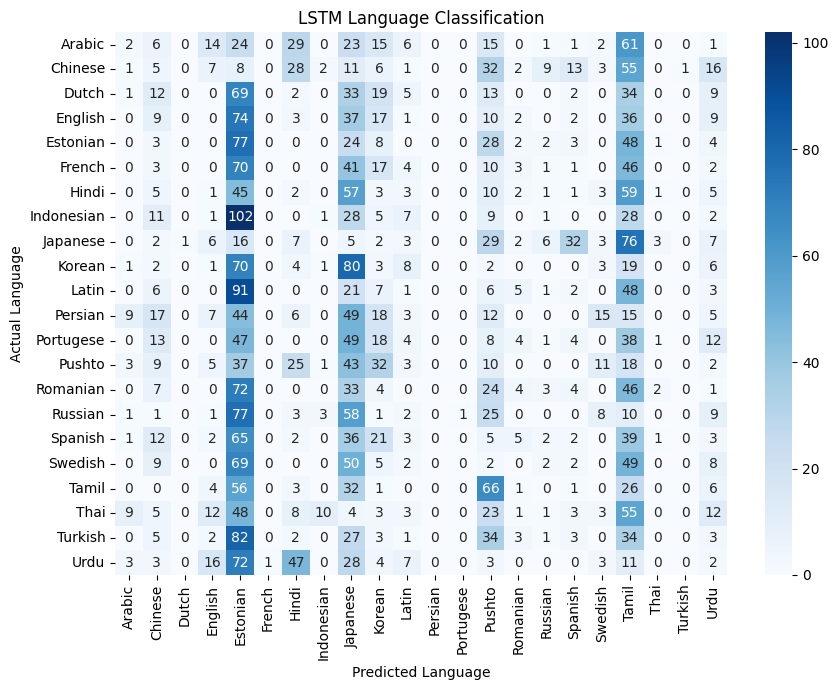

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.title("LSTM Language Classification")
plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.tight_layout()
plt.show()

In [ ]:
def predict_language(text):
    text = clean_text(text)

    sequence = tokenizer.texts_to_sequences([text])

    padded = pad_sequences(
        sequence,
        maxlen=max_len,
        padding="post",
        truncating="post"
    )

    probabilities = model.predict(padded, verbose=0)[0]

    predicted_index = np.argmax(probabilities)
    language = encoder.inverse_transform(
        [predicted_index]
    )[0]

    score = probabilities[predicted_index]

    return language, score


samples = [
    "The weather is beautiful today.",
    "Bonjour, comment allez-vous?",
    "Hola, me gusta aprender idiomas.",
    "வணக்கம், இன்று நல்ல நாள்.",
    "नमस्ते, मुझे पढ़ना पसंद है।"
]

for i, sample in enumerate(samples, start=1):
    language, score = predict_language(sample)

    print(f"\nSample {i}: {sample}")
    print("Predicted language:", language)
    print("Model score:", f"{score:.2%}")


Sample 1: The weather is beautiful today.
Predicted language: English
Model score: 67.50%

Sample 2: Bonjour, comment allez-vous?
Predicted language: Dutch
Model score: 81.75%

Sample 3: Hola, me gusta aprender idiomas.
Predicted language: Indonesian
Model score: 41.20%

Sample 4: வணக்கம், இன்று நல்ல நாள்.
Predicted language: Tamil
Model score: 99.94%

Sample 5: नमस्ते, मुझे पढ़ना पसंद है।
Predicted language: Hindi
Model score: 99.98%


In [ ]:
# Ensure model is saved successfully
model.save("language_lstm_model.keras")
print("Model saved successfully!")

# Download the file to your local computer
from google.colab import files
try:
    files.download("language_lstm_model.keras")
    print("Download started!")
except Exception as e:
    print("Error starting download:", e)

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started!


In [ ]:
from google.colab import files
import os

model_path = "/content/language_lstm_model.keras"
if os.path.exists(model_path):
    files.download(model_path)
else:
    print(f"File not found at {model_path}. Please make sure you have run the model.save() cell first.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>